=== THIS TABLE SHOWS THE ERRORS OF EACH METHOD AT SPECIFIED VALUES OF 'N' ===
------------------------------------------------------------------------------
n      Midpoint       Trapezoidal    Simpson        Gauss-2pt      Gauss-3pt     
------------------------------------------------------------------------------
4      2.7957e-03 3.1796e-03 1.4487e-02 5.3799e-04 2.1696e-06
8      1.6815e-04 1.9193e-04 8.0396e-04 3.2117e-05 3.4659e-08
16     1.0405e-05 1.1887e-05 4.8127e-05 1.9832e-06 5.4340e-10
32     6.4865e-07 7.4125e-07 2.9741e-06 1.2357e-07 8.4968e-12
64     4.0515e-08 4.6302e-08 1.8535e-07 7.7174e-09 1.3278e-13

Estimated Observed Convergence Rates (Slopes):
---------------------------------------------
Midpoint       : 4.02
Trapezoidal    : 4.02
Simpson        : 4.06
Gauss-2pt      : 4.02
Gauss-3pt      : 5.99


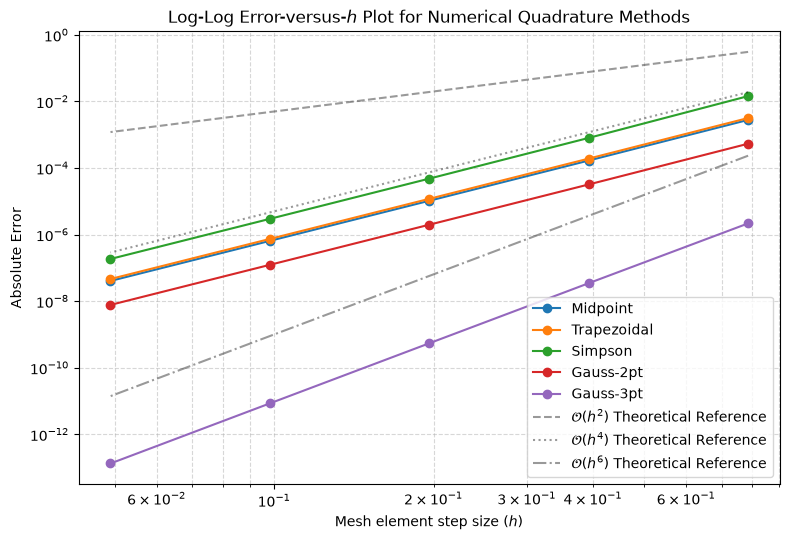

In [2]:
#THIS CELL HAS THE COMPUTATIONS FOR THIS PROBLEM

import numpy as np
import matplotlib.pyplot as plt

# 1. Define the integrand and analytical reference solution
def f(x):
    return (np.sin(x)**2) * np.exp(-x)

# True analytical integral over [0, pi]
true_integral = 0.4 * (1.0 - np.exp(-np.pi))

# 2. Quadrature Method Implementations
def composite_midpoint(f, a, b, n):
    h = (b - a) / n
    x = a + (np.arange(n) + 0.5) * h
    return h * np.sum(f(x))

def composite_trapezoidal(f, a, b, n):
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    return (h / 2.0) * (y[0] + 2.0 * np.sum(y[1:-1]) + y[-1])

def composite_simpson(f, a, b, n):
    if n % 2 != 0:
        raise ValueError("Simpson's rule requires an even number of intervals (n).")
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = f(x)
    return (h / 3.0) * (y[0] + 4.0 * np.sum(y[1:-1:2]) + 2.0 * np.sum(y[2:-1:2]) + y[-1])

def gauss_legendre_2point(f, a, b, n):
    roots, weights = np.polynomial.legendre.leggauss(2)
    h = (b - a) / n
    total_sum = 0.0
    for i in range(n):
        xi_L = a + i * h
        xi_R = xi_L + h
        x_mapped = 0.5 * h * roots + 0.5 * (xi_L + xi_R)
        total_sum += 0.5 * h * np.sum(weights * f(x_mapped))
    return total_sum

def gauss_legendre_3point(f, a, b, n):
    roots, weights = np.polynomial.legendre.leggauss(3)
    h = (b - a) / n
    total_sum = 0.0
    for i in range(n):
        xi_L = a + i * h
        xi_R = xi_L + h
        x_mapped = 0.5 * h * roots + 0.5 * (xi_L + xi_R)
        total_sum += 0.5 * h * np.sum(weights * f(x_mapped))
    return total_sum

# 3. Setup Mesh Resolutions and Error Arrays
a, b = 0.0, np.pi
n_values = np.array([4, 8, 16, 32, 64])
h_values = (b - a) / n_values

methods = {
    'Midpoint': (composite_midpoint, []),
    'Trapezoidal': (composite_trapezoidal, []),
    'Simpson': (composite_simpson, []),
    'Gauss-2pt': (gauss_legendre_2point, []),
    'Gauss-3pt': (gauss_legendre_3point, [])
}

# Run numerical calculations to populate errors
for n in n_values:
    for name, (func, errors) in methods.items():
        approx = func(f, a, b, n)
        abs_error = abs(approx - true_integral)
        errors.append(abs_error)

# 4. Print Summary Table & Convergence Rates
print("=== THIS TABLE SHOWS THE ERRORS OF EACH METHOD AT SPECIFIED VALUES OF 'N' ===")
print("-"*78)
print(f"{'n':<6} {'Midpoint':<14} {'Trapezoidal':<14} {'Simpson':<14} {'Gauss-2pt':<14} {'Gauss-3pt':<14}")
print("-" * 78)
for idx, n in enumerate(n_values):
    row_str = f"{n:<6} " + " ".join([f"{methods[m][1][idx]:.4e}" for m in methods])
    print(row_str)

print("\nEstimated Observed Convergence Rates (Slopes):")
print("-" * 45)
for name, (_, errors) in methods.items():
    slope, _ = np.polyfit(np.log(h_values), np.log(errors), 1)
    print(f"{name:<15}: {slope:.2f}")

# 5. Generate Log-Log Error-versus-h Plot
plt.figure(figsize=(8, 5.5))

# Plot experimental data
for name, (_, errors) in methods.items():
    plt.loglog(h_values, errors, 'o-', linewidth=1.5, label=f"{name}")

# Add theoretical reference slope lines for your LaTeX verification section
plt.loglog(h_values, 0.5 * h_values**2, '--', color='black', alpha=0.4, label=r'$\mathcal{O}(h^2)$ Theoretical Reference')
plt.loglog(h_values, 0.05 * h_values**4, ':', color='black', alpha=0.4, label=r'$\mathcal{O}(h^4)$ Theoretical Reference')
plt.loglog(h_values, 0.001 * h_values**6, '-.', color='black', alpha=0.4, label=r'$\mathcal{O}(h^6)$ Theoretical Reference')

plt.title('Log-Log Error-versus-$h$ Plot for Numerical Quadrature Methods')
plt.xlabel('Mesh element step size ($h$)')
plt.ylabel('Absolute Error')
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()

# Plot graph
plt.show()

